<a href="https://colab.research.google.com/github/palashDoshi1/CMPSC-448-Midterm-Project/blob/main/LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LSTM-Based LLM Attribution

**CMPSC 448 — Midterm Project**

**Research Question 1 (RQ1):** Can we identify which large language model generated a response using only its output text?

This notebook implements a Long Short-Term Memory (LSTM) neural network to classify responses into three model families: GPT, Claude, and Gemini.

The LSTM results will be compared with a Convolutional Neural Network (CNN) developed separately using the same dataset, vocabulary, preprocessing rules, and evaluation metrics.

### Experimental Configuration

- **Task:** Three-class text classification
- **Input:** LLM-generated response (`output`)
- **Target:** Generating model (`model`)
- **Framework:** PyTorch
- **Random seed:** 42
- **Model:** Single-layer LSTM with trainable embeddings

In [ ]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


## 1. Dataset Loading and Validation

The dataset contains 540 responses to 180 prompts, with one response from each of GPT, Claude, and Gemini per prompt.

We use three predefined datasets:

| Split | Responses | Purpose |
|---|---:|---|
| Training | 378 | Learn model parameters |
| Validation | 81 | Select the best checkpoint and monitor generalization |
| Testing | 81 | Evaluate final performance |

The existing splits are used without modification.

**Data leakage prevention:** Responses to the same prompt must remain within the same split. This prevents the classifier from encountering the same prompt in both training and evaluation.

The dataset includes the columns `prompt_id`, `category`, `model`, `input`, and `output`. For RQ1, only `output` is used as input to the classifier.

In [ ]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/palashDoshi1/CMPSC-448-Midterm-Project/main/data/"

train_df = pd.read_csv(BASE + "train.csv")
val_df = pd.read_csv(BASE + "validation.csv")
test_df = pd.read_csv(BASE + "test.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (378, 5)
Validation: (81, 5)
Testing: (81, 5)


In [ ]:
required = {"prompt_id", "category", "model", "input", "output"}

for frame in [train_df, val_df, test_df]:
    assert required.issubset(frame.columns)

train_ids = set(train_df["prompt_id"])
val_ids = set(val_df["prompt_id"])
test_ids = set(test_df["prompt_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

for frame in [train_df, val_df, test_df]:
    assert not frame.duplicated(["prompt_id", "model"]).any()
    assert frame.groupby("prompt_id")["model"].nunique().eq(3).all()

print("Splits verified: no prompt overlap.")

Splits verified: no prompt overlap.


## 2. Sequence Encoding and DataLoaders

Each response is converted into a sequence of integer token IDs using the shared vocabulary.

To standardize model inputs, sequences are truncated or padded to **512 tokens**:

- Responses longer than 512 tokens retain their first 512 tokens.
- Shorter responses are padded on the right with `<PAD>`.
- Unknown tokens are mapped to `<UNK>`.

The PyTorch Dataset returns the encoded sequence, its valid length, and the numerical class label.

### Class Mapping

| Model | Label |
|---|---:|
| GPT | 0 |
| Claude | 1 |
| Gemini | 2 |

DataLoaders use a batch size of 16. Training data is shuffled, while validation and test data are not.

In [ ]:

import os
import re
import json
import copy
import random
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
MAX_VOCAB = 10000
MAX_LEN = 512
EMBED_DIM = 128
HIDDEN_DIM = 128
BATCH_SIZE = 16
LR = 0.001
DROPOUT = 0.3
EPOCHS = 20
PATIENCE = 4

LABEL_MAP = {"gpt": 0, "claude": 1, "gemini": 2}
CLASS_NAMES = ["GPT", "Claude", "Gemini"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


Device: cuda


In [ ]:
for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(name, frame.shape)
    print("Columns:", frame.columns.tolist())

Train (378, 5)
Columns: ['prompt_id', 'category', 'model', 'input', 'output']
Validation (81, 5)
Columns: ['prompt_id', 'category', 'model', 'input', 'output']
Test (81, 5)
Columns: ['prompt_id', 'category', 'model', 'input', 'output']


## 3. Text Preprocessing and Vocabulary

LLM attribution may depend on writing-style characteristics such as capitalization, punctuation, Markdown formatting, and vocabulary choices.

We therefore avoid lowercasing, stemming, lemmatization, and stopword removal.

The shared tokenizer is:

`re.findall(r"\w+|[^\w\s]", str(text))`

This separates words and punctuation while retaining capitalization and symbols. Whitespace and line-break patterns are not explicitly represented as tokens.

The vocabulary is constructed using **training responses only**, preventing vocabulary information from the validation and test sets from entering training.

### Shared Vocabulary Settings

- Maximum vocabulary size: 10,000 tokens
- Padding token: `<PAD>` = 0
- Unknown token: `<UNK>` = 1
- Token ordering: Descending frequency, alphabetical order for ties
- Saved vocabulary: `data/vocab.json`

The CNN and LSTM use the same token-to-ID mapping to ensure comparable preprocessing.

In [ ]:

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text))

sample_tokens = tokenize(train_df["output"].iloc[0])

print("First 30 tokens:")
print(sample_tokens[:30])


First 30 tokens:
['#', '#', 'How', 'does', 'quarterback', 'performance', 'compare', 'with', 'coaching', 'strategy', 'in', 'determining', 'an', 'NFL', 'team', '’', 's', 'success', '?', 'Quarterback', 'performance', 'and', 'coaching', 'strategy', 'are', 'two', 'of', 'the', 'most', 'important']


In [ ]:

def build_vocab(texts, max_vocab=10000):
    counts = Counter()

    for text in texts:
        counts.update(tokenize(text))

    vocab = {"<PAD>": 0, "<UNK>": 1}

    # Deterministic order: frequency descending,
    # alphabetical order when frequencies tie.
    sorted_tokens = sorted(
        counts.items(),
        key=lambda item: (-item[1], item[0])
    )

    for token, frequency in sorted_tokens:
        if len(vocab) >= max_vocab:
            break

        if token not in vocab:
            vocab[token] = len(vocab)

    return vocab

vocab = build_vocab(train_df["output"], MAX_VOCAB)

print("Vocabulary size:", len(vocab))
print("First entries:", list(vocab.items())[:15])


Vocabulary size: 10000
First entries: [('<PAD>', 0), ('<UNK>', 1), (',', 2), ('.', 3), ('*', 4), ('-', 5), ('and', 6), ('the', 7), ('a', 8), ('to', 9), (':', 10), (')', 11), ('(', 12), ('|', 13), ('of', 14)]


In [ ]:

os.makedirs("/content/shared", exist_ok=True)

VOCAB_PATH = "/content/shared/vocab.json"

with open(VOCAB_PATH, "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False, indent=2)

print("Saved:", VOCAB_PATH)


Saved: /content/shared/vocab.json


In [ ]:

import json
from urllib.request import urlopen

url = (
    "https://raw.githubusercontent.com/"
    "palashDoshi1/CMPSC-448-Midterm-Project/main/data/vocab.json"
)

with urlopen(url) as response:
    vocab = json.load(response)

print("Vocabulary size:", len(vocab))


Vocabulary size: 10000


In [ ]:

MAX_LEN = 512

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text))

def encode_text(text):
    tokens = tokenize(text)[:MAX_LEN]

    ids = [vocab.get(token, 1) for token in tokens]

    if len(ids) == 0:
        ids = [1]

    length = len(ids)

    ids += [0] * (MAX_LEN - len(ids))

    return ids, length

ids, length = encode_text(train_df["output"].iloc[0])

print("Sequence length:", len(ids))
print("Actual tokens:", length)
print("First 20 IDs:", ids[:20])


Sequence length: 512
Actual tokens: 484
First 20 IDs: [16, 16, 191, 113, 789, 118, 540, 22, 284, 453, 17, 2194, 28, 525, 58, 582, 37, 226, 127, 2649]


In [ ]:

LABEL_MAP = {"gpt": 0, "claude": 1, "gemini": 2}
BATCH_SIZE = 16

class LLMDataset(Dataset):
    def __init__(self, df):
        self.texts = df["output"].tolist()
        self.labels = (
            df["model"]
            .str.strip()
            .str.lower()
            .map(LABEL_MAP)
            .tolist()
        )

        assert all(label is not None for label in self.labels)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids, length = encode_text(self.texts[idx])

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

train_loader = DataLoader(
    LLMDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    LLMDataset(val_df),
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    LLMDataset(test_df),
    batch_size=BATCH_SIZE
)

x, lengths, labels = next(iter(train_loader))

print("Inputs:", x.shape)
print("Lengths:", lengths.shape)
print("Labels:", labels.shape)


Inputs: torch.Size([16, 512])
Lengths: torch.Size([16])
Labels: torch.Size([16])


## 4. LSTM Model Architecture

The LSTM classifier consists of:

1. **Embedding layer:** Converts token IDs into trainable 128-dimensional vectors.
2. **LSTM layer:** Processes the token sequence using 128 hidden units.
3. **Final valid hidden state:** Represents the response after processing its non-padding tokens.
4. **Dropout layer (0.3):** Reduces reliance on individual learned features during training.
5. **Fully connected layer:** Produces three classification logits for GPT, Claude, and Gemini.

Packed sequences are used so that padding does not affect which hidden state is selected as the final response representation.

The model uses randomly initialized embeddings rather than pretrained language representations. This allows the CNN and LSTM comparison to focus on the architectures under a shared experimental setup.

In [ ]:
EMBED_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.3

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=EMBED_DIM,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=EMBED_DIM,
            hidden_size=HIDDEN_DIM,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(HIDDEN_DIM, 3)

    def forward(self, x, lengths):
        embedded = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        final_hidden = hidden[-1]

        output = self.dropout(final_hidden)
        logits = self.fc(output)

        return logits

model = LSTMClassifier(
    vocab_size=len(vocab)
).to(device)

print(model)
print("Device:", device)


LSTMClassifier(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)
Device: cuda


In [ ]:

model.eval()

with torch.no_grad():
    logits = model(
        x.to(device),
        lengths.to(device)
    )

print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Predicted classes:", logits.argmax(dim=1).cpu().tolist())


Input shape: torch.Size([16, 512])
Output shape: torch.Size([16, 3])
Predicted classes: [2, 2, 2, 2, 2, 2, 2, 1, 2, 0, 2, 1, 2, 2, 2, 1]


In [ ]:

from sklearn.metrics import accuracy_score, f1_score

def evaluate_model(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for inputs, lengths, labels in loader:
            inputs = inputs.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            outputs = model(inputs, lengths)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(
                predictions.cpu().numpy()
            )

    avg_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "labels": all_labels,
        "predictions": all_predictions
    }


## 5. Model Training and Early Stopping

The LSTM is trained using the following configuration:

| Hyperparameter | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss function | CrossEntropyLoss |
| Batch size | 16 |
| Maximum epochs | 20 |
| Early-stopping patience | 4 |
| Checkpoint selection | Highest validation macro-F1 |

After each epoch, we calculate training loss, validation loss, validation accuracy, and validation macro-F1.

**Macro-F1** gives equal importance to all three model families by averaging their individual F1 scores.

Early stopping prevents unnecessary training when validation macro-F1 stops improving. The weights from the epoch with the highest validation macro-F1 are restored for subsequent evaluation.

In [ ]:

import copy

LEARNING_RATE = 0.001
MAX_EPOCHS = 20
PATIENCE = 4

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

best_val_f1 = -1
best_model_state = None
best_epoch = None
patience_counter = 0

history = []

for epoch in range(MAX_EPOCHS):
    model.train()

    running_loss = 0.0

    for inputs, lengths, labels in train_loader:
        inputs = inputs.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs, lengths)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    val_results = evaluate_model(
        model,
        val_loader,
        criterion
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_macro_f1": val_results["macro_f1"]
    })

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_results['loss']:.4f} | "
        f"Val Accuracy: {val_results['accuracy']:.4f} | "
        f"Val Macro-F1: {val_results['macro_f1']:.4f}"
    )

    if val_results["macro_f1"] > best_val_f1:
        best_val_f1 = val_results["macro_f1"]
        best_model_state = copy.deepcopy(
            model.state_dict()
        )
        best_epoch = epoch + 1
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_model_state)

history_df = pd.DataFrame(history)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", best_val_f1)


Epoch 01 | Train Loss: 1.0520 | Val Loss: 1.0051 | Val Accuracy: 0.4938 | Val Macro-F1: 0.4611
Epoch 02 | Train Loss: 0.9231 | Val Loss: 0.8723 | Val Accuracy: 0.5679 | Val Macro-F1: 0.5472
Epoch 03 | Train Loss: 0.7577 | Val Loss: 0.7796 | Val Accuracy: 0.6667 | Val Macro-F1: 0.6716
Epoch 04 | Train Loss: 0.5257 | Val Loss: 0.7356 | Val Accuracy: 0.6914 | Val Macro-F1: 0.6873
Epoch 05 | Train Loss: 0.3247 | Val Loss: 0.7696 | Val Accuracy: 0.7160 | Val Macro-F1: 0.7203
Epoch 06 | Train Loss: 0.2069 | Val Loss: 0.8243 | Val Accuracy: 0.7037 | Val Macro-F1: 0.6944
Epoch 07 | Train Loss: 0.1239 | Val Loss: 0.9249 | Val Accuracy: 0.7160 | Val Macro-F1: 0.7073
Epoch 08 | Train Loss: 0.0603 | Val Loss: 1.1386 | Val Accuracy: 0.6790 | Val Macro-F1: 0.6727
Epoch 09 | Train Loss: 0.0328 | Val Loss: 1.3199 | Val Accuracy: 0.6790 | Val Macro-F1: 0.6756
Early stopping triggered.

Training complete.
Best epoch: 5
Best validation macro-F1: 0.7203197663246089


## 6. Training and Validation Analysis

The learning curves compare training loss with validation loss and show how validation accuracy and macro-F1 change across epochs.

A decreasing training loss accompanied by increasing validation loss can indicate overfitting. We use these curves to assess whether the model generalizes beyond its training examples.

The final checkpoint is selected using validation macro-F1 rather than training loss.

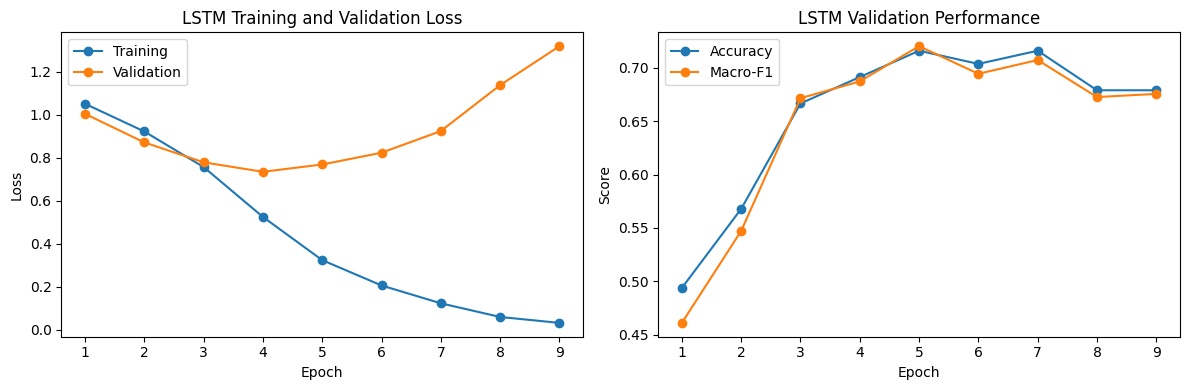

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation"
)

axes[0].set_title("LSTM Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    marker="o",
    label="Macro-F1"
)

axes[1].set_title("LSTM Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()

plt.tight_layout()
plt.show()


Test Loss: 0.7819
Test Accuracy: 0.7160
Test Macro-F1: 0.7141

Classification Report:
              precision    recall  f1-score   support

         GPT       0.71      0.63      0.67        27
      Claude       0.70      0.70      0.70        27
      Gemini       0.73      0.81      0.77        27

    accuracy                           0.72        81
   macro avg       0.72      0.72      0.71        81
weighted avg       0.72      0.72      0.71        81



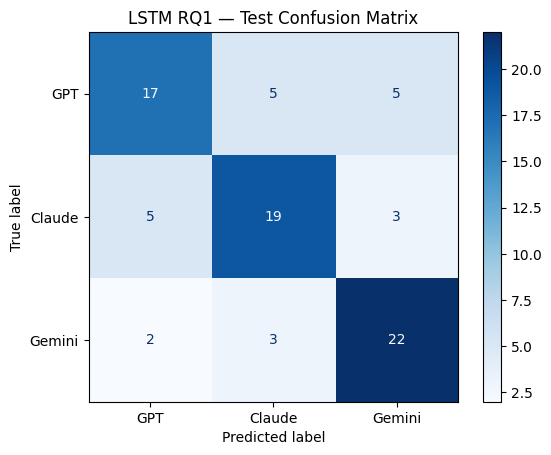

In [ ]:

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

# Evaluate the selected best checkpoint on held-out test data.
test_results = evaluate_model(
    model,
    test_loader,
    criterion
)

print(f"Test Loss: {test_results['loss']:.4f}")
print(f"Test Accuracy: {test_results['accuracy']:.4f}")
print(f"Test Macro-F1: {test_results['macro_f1']:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_results["labels"],
        test_results["predictions"],
        labels=[0, 1, 2],
        target_names=["GPT", "Claude", "Gemini"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    test_results["labels"],
    test_results["predictions"],
    labels=[0, 1, 2],
    display_labels=["GPT", "Claude", "Gemini"],
    cmap="Blues"
)

plt.title("LSTM RQ1 — Test Confusion Matrix")
plt.show()


### RQ1 Validation Results and Interpretation

The output-only LSTM achieved:

| Metric | Result |
|---|---:|
| Validation accuracy | 71.60% |
| Validation macro-F1 | 0.7203 |
| Best checkpoint | Epoch 5 |

These results are substantially above the 33.3% chance-level accuracy baseline for balanced three-class classification.

The model appears to learn distinguishing characteristics of GPT, Claude, and Gemini responses. However, validation performance alone does not establish final generalization performance.

The training curves suggest some overfitting, making checkpoint selection through early stopping important.

These findings are preliminary until the selected checkpoint is evaluated on the held-out test set and compared with the CNN.

Validation accuracy: 0.7160493827160493
Validation macro-F1: 0.7203197663246089
              precision    recall  f1-score   support

         GPT       0.67      0.67      0.67        27
      Claude       0.91      0.74      0.82        27
      Gemini       0.62      0.74      0.68        27

    accuracy                           0.72        81
   macro avg       0.73      0.72      0.72        81
weighted avg       0.73      0.72      0.72        81



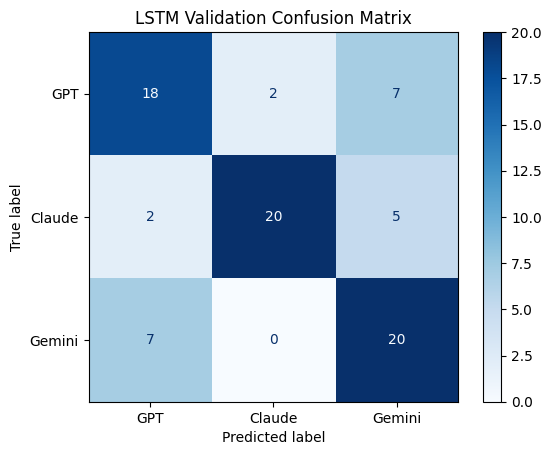

In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

val_results = evaluate_model(
    model,
    val_loader,
    criterion
)

print("Validation accuracy:", val_results["accuracy"])
print("Validation macro-F1:", val_results["macro_f1"])

print(
    classification_report(
        val_results["labels"],
        val_results["predictions"],
        labels=[0, 1, 2],
        target_names=["GPT", "Claude", "Gemini"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    val_results["labels"],
    val_results["predictions"],
    labels=[0, 1, 2],
    display_labels=["GPT", "Claude", "Gemini"],
    cmap="Blues"
)

plt.title("LSTM Validation Confusion Matrix")
plt.show()


## 8. Final Test Evaluation and CNN Comparison

The held-out test set will be used to report final RQ1 performance after the LSTM configuration is finalized.

The final evaluation will include test accuracy, test macro-F1, per-class precision and recall, a classification report, and a confusion matrix.

The LSTM will be compared with Palash's CNN using identical data splits, label mapping, tokenization, vocabulary, sequence length, and evaluation metrics.

The two architectures will be compared to investigate whether recurrent sequence modeling or convolutional feature extraction is more effective for identifying the generating LLM.


## RQ2: Input-Only vs. Output-Only vs. Combined Input/Output

### Research Question

Does using the original prompt, the generated response, or both improve the ability of an LSTM model to identify which LLM produced a response?

### Experimental Setup

We compare three input configurations:

- **Input-only:** The original prompt (`input`).
- **Output-only:** The generated response (`output`), using the completed RQ1 LSTM results.
- **Combined:** The original prompt and generated response separated by a special `[SEP]` token.

All experiments use the existing training, validation, and test splits to prevent data leakage. The LSTM architecture, hyperparameters, and label mapping remain consistent with RQ1.

For the new input-only and combined experiments, separate vocabularies are constructed using only the training data. The maximum encoded sequence length remains 512 tokens. In the combined configuration, space is reserved for both prompt and response tokens.

### Model Training

Two additional LSTM models are trained: one using only prompts and another using both prompts and responses. The output-only results from RQ1 are reused as the baseline.

Each model is trained using Adam with a learning rate of 0.001, a batch size of 16, and a maximum of 20 epochs. Early stopping uses a patience of four epochs, and the checkpoint with the highest validation macro-F1 is selected.

### Evaluation

The models are evaluated using accuracy, macro-F1, per-class precision and recall, and confusion matrices.

The input-only experiment serves as a control because each prompt appears with responses from all three LLMs. Therefore, prompt content alone should not provide a reliable signal for identifying the generating model.


In [ ]:
# RQ2 settings: reuse all imports and model definitions from RQ1.
RQ2_PROMPT_BUDGET = 128
RQ2_RESPONSE_BUDGET = 383
RQ2_SEED = 42
assert RQ2_PROMPT_BUDGET + 1 + RQ2_RESPONSE_BUDGET == MAX_LEN
assert all(name in globals() for name in ["train_df", "val_df", "test_df", "LSTMClassifier", "evaluate_model", "tokenize"])
print("RQ2 setup ready. No imports or CSV reloading required.")


RQ2 setup ready. No imports or CSV reloading required.


In [ ]:
def rq2_tokens(row, mode):
    if mode == "input":
        return tokenize(row["input"])[:MAX_LEN]
    if mode == "combined":
        return (tokenize(row["input"])[:RQ2_PROMPT_BUDGET]
                + ["[SEP]"]
                + tokenize(row["output"])[:RQ2_RESPONSE_BUDGET])
    raise ValueError(mode)

def rq2_build_vocab(frame, mode):
    counts = Counter()
    for row in frame.to_dict("records"):
        counts.update(rq2_tokens(row, mode))
    result = {"<PAD>": 0, "<UNK>": 1}
    if mode == "combined":
        result["[SEP]"] = 2
    for token, _ in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0])):
        if len(result) >= 10000:
            break
        if token not in result:
            result[token] = len(result)
    return result

rq2_vocab_input = rq2_build_vocab(train_df, "input")
rq2_vocab_combined = rq2_build_vocab(train_df, "combined")
assert rq2_vocab_combined["[SEP]"] == 2
os.makedirs("/content/data", exist_ok=True)
for name, mapping in [("input", rq2_vocab_input), ("combined", rq2_vocab_combined)]:
    path = f"/content/data/vocab_{name}.json"
    with open(path, "w", encoding="utf-8") as file:
        json.dump(mapping, file, ensure_ascii=False, indent=2)
    print(path, "size:", len(mapping))
print("Completed!")


/content/data/vocab_input.json size: 1782
/content/data/vocab_combined.json size: 10000
Completed!


In [ ]:
class RQ2Dataset(Dataset):
    def __init__(self, frame, mapping, mode):
        self.rows = frame.to_dict("records")
        self.mapping = mapping
        self.mode = mode

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        tokens = rq2_tokens(row, self.mode)
        ids = [self.mapping.get(t, 1) for t in tokens] or [1]
        ids = ids[:MAX_LEN]
        length = len(ids)
        ids += [0] * (MAX_LEN - length)
        label = LABEL_MAP[str(row["model"]).strip().lower()]
        return (torch.tensor(ids, dtype=torch.long),
                torch.tensor(length, dtype=torch.long),
                torch.tensor(label, dtype=torch.long))

def rq2_loaders(mode, mapping):
    return (
        DataLoader(RQ2Dataset(train_df, mapping, mode), batch_size=BATCH_SIZE, shuffle=True),
        DataLoader(RQ2Dataset(val_df, mapping, mode), batch_size=BATCH_SIZE, shuffle=False),
        DataLoader(RQ2Dataset(test_df, mapping, mode), batch_size=BATCH_SIZE, shuffle=False)
    )

for mode, mapping in [("input", rq2_vocab_input), ("combined", rq2_vocab_combined)]:
    tr, va, te = rq2_loaders(mode, mapping)
    batch = next(iter(tr))
    print(mode, "batch shape:", batch[0].shape, "splits:", len(tr.dataset), len(va.dataset), len(te.dataset))


input batch shape: torch.Size([16, 512]) splits: 378 81 81
combined batch shape: torch.Size([16, 512]) splits: 378 81 81


In [ ]:
def rq2_train(mode, mapping):
    random.seed(RQ2_SEED)
    np.random.seed(RQ2_SEED)
    torch.manual_seed(RQ2_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RQ2_SEED)

    tr, va, te = rq2_loaders(mode, mapping)
    rq2_model = LSTMClassifier(len(mapping)).to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(rq2_model.parameters(), lr=LEARNING_RATE)
    best_f1, best_state, best_epoch, waiting = -1.0, None, None, 0
    records = []

    for epoch in range(1, MAX_EPOCHS + 1):
        rq2_model.train()
        total = 0.0
        for inputs, lengths, labels in tr:
            inputs, lengths, labels = inputs.to(device), lengths.to(device), labels.to(device)
            opt.zero_grad()
            logits = rq2_model(inputs, lengths)
            loss = loss_fn(logits, labels)
            loss.backward()
            opt.step()
            total += loss.item() * labels.size(0)

        val = evaluate_model(rq2_model, va, loss_fn)
        record = {"epoch": epoch, "train_loss": total / len(tr.dataset),
                  "val_loss": val["loss"], "val_accuracy": val["accuracy"],
                  "val_macro_f1": val["macro_f1"]}
        records.append(record)
        print(f"{mode:8s} epoch {epoch:02d} | train loss {record['train_loss']:.4f} | "
              f"val loss {val['loss']:.4f} | val acc {val['accuracy']:.4f} | val F1 {val['macro_f1']:.4f}")

        if val["macro_f1"] > best_f1:
            best_f1 = val["macro_f1"]
            best_epoch = epoch
            best_state = copy.deepcopy(rq2_model.state_dict())
            waiting = 0
        else:
            waiting += 1
        if waiting >= PATIENCE:
            print("Early stopping")
            break

    rq2_model.load_state_dict(best_state)
    return {"model": rq2_model, "test_loader": te,
            "history": pd.DataFrame(records), "best_epoch": best_epoch,
            "best_val_f1": best_f1}

rq2_input_run = rq2_train("input", rq2_vocab_input)
rq2_combined_run = rq2_train("combined", rq2_vocab_combined)

os.makedirs("/content/results", exist_ok=True)
for mode, run in [("input", rq2_input_run), ("combined", rq2_combined_run)]:
    torch.save(run["model"].state_dict(), f"/content/results/lstm_rq2_{mode}_best.pt")
    run["history"].to_csv(f"/content/results/lstm_rq2_{mode}_history.csv", index=False)
    print(mode, "best epoch:", run["best_epoch"], "best validation F1:", run["best_val_f1"])


input    epoch 01 | train loss 1.1257 | val loss 1.1003 | val acc 0.3333 | val F1 0.2483
input    epoch 02 | train loss 1.1135 | val loss 1.0997 | val acc 0.3333 | val F1 0.2659
input    epoch 03 | train loss 1.1114 | val loss 1.0992 | val acc 0.3333 | val F1 0.2749
input    epoch 04 | train loss 1.1039 | val loss 1.0990 | val acc 0.3333 | val F1 0.2833
input    epoch 05 | train loss 1.1077 | val loss 1.0994 | val acc 0.3333 | val F1 0.2644
input    epoch 06 | train loss 1.1055 | val loss 1.0988 | val acc 0.3333 | val F1 0.2730
input    epoch 07 | train loss 1.1121 | val loss 1.0994 | val acc 0.3333 | val F1 0.2833
input    epoch 08 | train loss 1.1019 | val loss 1.0990 | val acc 0.3333 | val F1 0.3270
input    epoch 09 | train loss 1.1016 | val loss 1.0993 | val acc 0.3333 | val F1 0.3288
input    epoch 10 | train loss 1.1045 | val loss 1.0990 | val acc 0.3333 | val F1 0.2483
input    epoch 11 | train loss 1.1030 | val loss 1.0988 | val acc 0.3333 | val F1 0.2644
input    epoch 12 | t

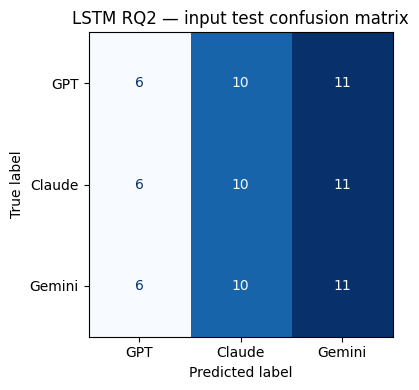

input test accuracy: 0.3333333333333333 macro-F1: 0.32807017543859646
              precision    recall  f1-score   support

         GPT       0.33      0.22      0.27        27
      Claude       0.33      0.37      0.35        27
      Gemini       0.33      0.41      0.37        27

    accuracy                           0.33        81
   macro avg       0.33      0.33      0.33        81
weighted avg       0.33      0.33      0.33        81



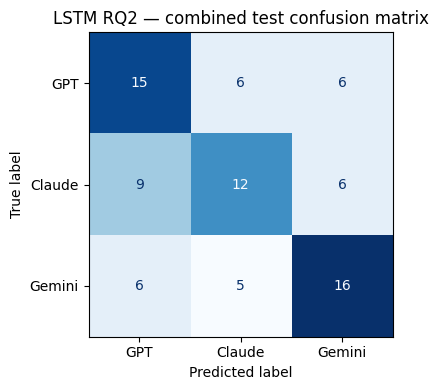

combined test accuracy: 0.5308641975308642 macro-F1: 0.529377990430622
              precision    recall  f1-score   support

         GPT       0.50      0.56      0.53        27
      Claude       0.52      0.44      0.48        27
      Gemini       0.57      0.59      0.58        27

    accuracy                           0.53        81
   macro avg       0.53      0.53      0.53        81
weighted avg       0.53      0.53      0.53        81

          experiment  test_accuracy  test_macro_f1
0         Input-only       0.333333       0.328070
1  Output-only (RQ1)       0.716049       0.714100
2           Combined       0.530864       0.529378


In [ ]:
rq2_test_results = {}
for mode, run in [("input", rq2_input_run), ("combined", rq2_combined_run)]:
    result = evaluate_model(run["model"], run["test_loader"], nn.CrossEntropyLoss())
    cm = confusion_matrix(result["labels"], result["predictions"], labels=[0, 1, 2])
    report = classification_report(result["labels"], result["predictions"],
                                   labels=[0, 1, 2], target_names=["GPT", "Claude", "Gemini"],
                                   zero_division=0)
    summary = {"model": "LSTM", "experiment": f"RQ2_{mode}",
               "test_accuracy": float(result["accuracy"]),
               "test_macro_f1": float(result["macro_f1"]),
               "test_loss": float(result["loss"]),
               "confusion_matrix": cm.tolist(),
               "class_order": ["GPT", "Claude", "Gemini"],
               "best_epoch": run["best_epoch"],
               "best_validation_macro_f1": float(run["best_val_f1"])}
    rq2_test_results[mode] = summary
    with open(f"/content/results/lstm_rq2_{mode}_metrics.json", "w") as file:
        json.dump(summary, file, indent=2)
    with open(f"/content/results/lstm_rq2_{mode}_report.txt", "w") as file:
        file.write(report)
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(cm, display_labels=["GPT", "Claude", "Gemini"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"LSTM RQ2 — {mode} test confusion matrix")
    fig.tight_layout()
    fig.savefig(f"/content/results/lstm_rq2_{mode}_confusion_matrix.png", dpi=160)
    plt.show()
    print(mode, "test accuracy:", summary["test_accuracy"],
          "macro-F1:", summary["test_macro_f1"])
    print(report)

print(pd.DataFrame([
    {"experiment": "Input-only", "test_accuracy": rq2_test_results["input"]["test_accuracy"],
     "test_macro_f1": rq2_test_results["input"]["test_macro_f1"]},
    {"experiment": "Output-only (RQ1)", "test_accuracy": 58 / 81, "test_macro_f1": 0.7141},
    {"experiment": "Combined", "test_accuracy": rq2_test_results["combined"]["test_accuracy"],
     "test_macro_f1": rq2_test_results["combined"]["test_macro_f1"]}
]))
